# Williams-Otto Physics-Informed Training (Phase 4)

This notebook trains a Williams-Otto tanh surrogate with an explicit **physics
penalty** and compares it head-to-head against a plain, data-only tanh surrogate,
then embeds both in the downstream profit optimization.

The two models are matched on everything except the physics penalty: same
`[16, 16]` tanh architecture, same data split, and — as in notebooks 01 and 05 —
the same `8×` **constraint-output weighting** on `XA` and `XG`. So the comparison
isolates one question: does adding differentiable mass-fraction *closure* and
*operating-bound* penalties to training reduce physical inconsistency without
costing prediction accuracy or downstream optimization value? The short answer
below is *yes, modestly* — the penalty trims the steady-state balance residual at
almost no accuracy cost, but at the scale of this problem it barely moves the
embedded optimum, which is limited more by the PWL discretization than by training.


## Setup

In [68]:
from __future__ import annotations

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from pwlnet import DenseLayer, NetworkDefinition, OffsetScaler, PhysicsSpec, PWLNet
from pwlnet.benchmarking.metrics import metrics_table
from pwlnet.data import train_val_test_split
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    profit,
    residuals,
    solve_steady_state,
)
from pwlnet.processes.williams_otto.pyomo_model import solve_surrogate_optimization_model

RANDOM_SEED = 2479085
rng = np.random.default_rng(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid")

params = WilliamsOttoParameters()
params

WilliamsOttoParameters(fa=1.8275, holdup=2105.2, a1=1659900.0, b1=6666.7, a2=721170000.0, b2=8333.3, a3=2674500000000.0, b3=11111.0, price_p=1043.38, price_e=20.92, cost_a=79.23, cost_b=118.34, xa_max=0.12, xg_max=0.08, fb_bounds=(4.0, 7.0), tr_bounds=(70.0, 100.0))

## Data

We keep the same supervised target as the earlier Williams-Otto notebooks: inputs are `(FB, TR)` and outputs are the six reactor mass fractions `(XA, XB, XC, XE, XG, XP)`. The extra `profit` and `residual_inf_norm` columns are generated by the exact simulator and used only for diagnostics.

In [69]:
DATA_CONFIG = dict(n_samples=240, method="lhs", random_state=RANDOM_SEED)
data = generate_dataset(**DATA_CONFIG, as_frame=True)
split = train_val_test_split(data, val_size=0.2, test_size=0.2, random_state=RANDOM_SEED)
train_df, val_df, test_df = split.train, split.validation, split.test

X_train = train_df[INPUT_NAMES].to_numpy(dtype=float)
y_train = train_df[OUTPUT_NAMES].to_numpy(dtype=float)
X_val = val_df[INPUT_NAMES].to_numpy(dtype=float)
y_val = val_df[OUTPUT_NAMES].to_numpy(dtype=float)
X_test = test_df[INPUT_NAMES].to_numpy(dtype=float)
y_test = test_df[OUTPUT_NAMES].to_numpy(dtype=float)

data.describe().T

,count,mean,std,min,25%,50%,75%,max
FB,240.0,5.500038e+00,8.678577e-01,4.005556e+00,4.752312e+00,5.501918e+00,6.245400e+00,6.999369e+00
TR,240.0,8.499961e+01,8.680673e+00,7.008269e+01,7.749071e+01,8.503715e+01,9.249565e+01,9.994554e+01
XA,240.0,9.230359e-02,2.476273e-02,4.700372e-02,7.328842e-02,8.966428e-02,1.109846e-01,1.568011e-01
XB,240.0,4.597717e-01,6.912532e-02,2.934303e-01,4.105422e-01,4.672529e-01,5.163621e-01,6.009196e-01
XC,240.0,1.831503e-02,6.813541e-03,7.580344e-03,1.237896e-02,1.727722e-02,2.374245e-02,3.585062e-02
XE,240.0,2.531599e-01,3.617033e-02,1.650218e-01,2.271862e-01,2.546875e-01,2.814171e-01,3.287031e-01
XG,240.0,7.480468e-02,3.621131e-02,1.787743e-02,4.612500e-02,6.920648e-02,9.764066e-02,1.847715e-01
XP,240.0,1.016451e-01,7.161996e-03,7.655177e-02,9.820318e-02,1.035470e-01,1.072894e-01,1.102255e-01
profit,240.0,1.614388e+01,6.546585e+01,-2.266835e+02,-1.625334e+01,3.562528e+01,6.805025e+01,8.826475e+01
residual_inf_norm,240.0,1.798955e-14,6.371419e-14,2.775558e-17,3.816392e-16,7.771561e-16,4.024558e-15,5.504486e-13


## Physics Diagnostics

The exact simulator solves six steady-state balances, so exact training labels have near-zero residuals. A surrogate prediction can have low MSE while violating those balances. Phase 4 measures that gap directly.

In [70]:
def residual_matrix(X, y, params=params):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    y = np.atleast_2d(np.asarray(y, dtype=float))
    return np.vstack([
        residuals(y_i, fb=float(x_i[0]), tr=float(x_i[1]), params=params)
        for x_i, y_i in zip(X, y)
    ])


def physics_report(name, X, y_pred, params=params):
    y_pred = np.atleast_2d(np.asarray(y_pred, dtype=float))
    r = residual_matrix(X, y_pred, params=params)
    eff_flow = params.fa + X[:, 0]
    closure = y_pred.sum(axis=1) - 1.0
    xa_violation = np.maximum(y_pred[:, OUTPUT_NAMES.index("XA")] - params.xa_max, 0.0)
    xg_violation = np.maximum(y_pred[:, OUTPUT_NAMES.index("XG")] - params.xg_max, 0.0)
    return {
        "model": name,
        "balance max |r| [kg/s]": float(np.max(np.abs(r))),
        "balance mean ||r/F||_2": float(np.mean(np.linalg.norm(r / eff_flow[:, None], axis=1))),
        "closure max |sumX-1|": float(np.max(np.abs(closure))),
        "XA max violation": float(np.max(xa_violation)),
        "XG max violation": float(np.max(xg_violation)),
    }

physics_report("exact labels", X_test, y_test)

{'model': 'exact labels',
 'balance max |r| [kg/s]': 5.135891711915974e-13,
 'balance mean ||r/F||_2': 4.001026039309653e-15,
 'closure max |sumX-1|': 2.220446049250313e-16,
 'XA max violation': 0.03680110823533195,
 'XG max violation': 0.08909958616569892}

## Constraint-output weighting

As in notebooks 01 and 05, we up-weight the two **constraint outputs** `XA` and
`XG` `8×` in the supervised data loss. The economic optimum sits right on the
`XA <= 0.12` and `XG <= 0.08` operating limits, so the surrogate is only useful
if it reproduces those two mass fractions accurately near the boundary. The
weights are renormalized to mean 1.0, so the data-loss magnitude (and effective
learning rate) are unchanged — only the *relative* emphasis shifts.

We apply the **same** weighting to both the plain baseline and the
physics-informed model, so the only difference between the two stays the physics
penalty. For the physics model the weighting is complementary to the operating-
bound penalty: the weighting sharpens *where* the learned `XA`/`XG` boundaries
fall, while the penalty discourages predicting them *above* the limit.


In [71]:
# Up-weight the two constraint outputs (XA, XG) in the supervised data loss,
# exactly as in notebooks 01 and 05. The weight vector is in OUTPUT_NAMES order;
# both trainers renormalize it to mean 1.0 internally, so the data-loss
# magnitude is unchanged -- only the relative emphasis shifts. We use the SAME
# weighting for the plain baseline and the physics-informed model so the only
# difference between them stays the physics penalty.
CONSTRAINT_OUTPUTS = ["XA", "XG"]   # outputs that appear in XA <= 0.12, XG <= 0.08
CONSTRAINT_WEIGHT = 8.0

output_loss_weights = np.ones(len(OUTPUT_NAMES))
for _name in CONSTRAINT_OUTPUTS:
    output_loss_weights[OUTPUT_NAMES.index(_name)] = CONSTRAINT_WEIGHT
print("per-output loss weights: "
      + ", ".join(f"{n}={w:g}" for n, w in zip(OUTPUT_NAMES, output_loss_weights)))


per-output loss weights: XA=8, XB=1, XC=1, XE=1, XG=8, XP=1


## Data-Only Baseline

The control case: a tanh surrogate trained on supervised MSE with the **same
`XA`/`XG` constraint-output weighting** as the physics model, but **no** physics
penalty. The per-output test MAE confirms the weighting does its job — `XA`
(2.4e-4) and `XG` (3.5e-4) land among the most accurate of the six outputs, even
though the constraint boundary is the sparsest, hardest-to-fit part of the input
box. Overall test MAE is 4.3e-4 (R² ≈ 0.9996).


In [72]:
plain = PWLNet.train(
    X_train,
    y_train,
    hidden_layers=[16, 16],
    activation="tanh",
    loss="mse",
    epochs=1000,
    batch_size=32,
    validation_data=(X_val, y_val),
    early_stopping_patience=40,
    random_seed=RANDOM_SEED,
    verbose=0,
    output_loss_weights=output_loss_weights,
)

print(plain.summary())
print(f"Keras/core max prediction difference: {plain.trainer.equivalence_error_:.3e}")

# Per-output test MAE, so the effect of up-weighting XA/XG is visible.
plain_per_output_mae = np.abs(plain.predict(X_test) - y_test).mean(axis=0)
print("plain per-output test MAE:")
for _n, _mae in zip(OUTPUT_NAMES, plain_per_output_mae):
    _tag = "  <-- constraint (up-weighted)" if _n in CONSTRAINT_OUTPUTS else ""
    print(f"  {_n}: {_mae:.3e}{_tag}")

plain_metrics = metrics_table({
    "plain train": (y_train, plain.predict(X_train)),
    "plain validation": (y_val, plain.predict(X_val)),
    "plain test": (y_test, plain.predict(X_test)),
})
plain_metrics

NetworkDefinition: 2 inputs -> 6 outputs, 3 layers, 32 hidden neurons, 422 parameters
layer   n_in  n_out activation   params
    0      2     16       tanh       48
    1     16     16       tanh      272
    2     16      6     linear      102
Keras/core max prediction difference: 1.774e-08
plain per-output test MAE:
  XA: 2.414e-04  <-- constraint (up-weighted)
  XB: 7.577e-04
  XC: 1.151e-04
  XE: 8.725e-04
  XG: 3.485e-04  <-- constraint (up-weighted)
  XP: 2.545e-04


,split,MAE,MSE,RMSE,R2,n_samples
0,plain train,0.000334,2.763538e-07,0.000526,0.999796,144
1,plain validation,0.000372,3.099681e-07,0.000557,0.999745,48
2,plain test,0.000432,6.247201e-07,0.000790,0.999565,48


## Physics-Informed Training Loop

The physics-informed model shares the baseline's architecture, scalers, and
`XA`/`XG` constraint weighting, but adds a composite objective built from generic
affine residuals:

```text
constraint-weighted scaled data MSE
+ lambda_closure * MSE(XA + XB + XC + XE + XG + XP - 1)
+ lambda_bounds  * MSE(max(XA - XA_max, 0), max(XG - XG_max, 0))
```

The closure and operating-bound terms are declared with the high-level
`PhysicsSpec` API by variable name; PWLNet translates them into affine residuals
and differentiable TensorFlow loss terms, evaluated in original physical units
(the data loss stays in scaled space). The nonlinear Williams-Otto balance
residuals are reported below only as diagnostics — they are *not* part of the
training objective.

`lambda_closure` and `lambda_bounds` are tuned on the validation set: keep every
candidate within a 10% tolerance of the best validation data-loss, then pick the
one with the smallest validation physics score. As the table shows, that tradeoff
is essentially flat here, so the chosen weights are one of many near-ties.


In [ ]:
generic_physics = (
    PhysicsSpec(input_names=INPUT_NAMES, output_names=OUTPUT_NAMES)
    .closure(
        OUTPUT_NAMES,
        total=1.0,
        name="closure",
        loss="mse",
    )
    .upper_bounds(
        {"XA": params.xa_max, "XG": params.xg_max},
        name="bounds",
        loss="mse",
    )
)


LAMBDA_SWEEP_GRID = [
    {"closure": closure, "bounds": bounds}
    # for closure in [0.0, 0.01, 0.05, 0.10, 0.25]
    for closure in [0.5, 0.6, 0.7]
    for bounds in [11,12,13]
]
LAMBDA_SELECTION_DATA_TOLERANCE = 0.10


def validation_physics_score(y_pred, X=X_val, params=params):
    y_pred = np.atleast_2d(np.asarray(y_pred, dtype=float))
    residual = residual_matrix(X, y_pred, params=params)
    eff_flow = params.fa + X[:, 0]
    closure = y_pred.sum(axis=1) - 1.0
    xa_violation = np.maximum(y_pred[:, OUTPUT_NAMES.index("XA")] - params.xa_max, 0.0)
    xg_violation = np.maximum(y_pred[:, OUTPUT_NAMES.index("XG")] - params.xg_max, 0.0)
    bound_violation = np.column_stack([xa_violation, xg_violation])
    return {
        "closure_rmse": float(np.sqrt(np.mean(np.square(closure)))),
        "bound_rmse": float(np.sqrt(np.mean(np.square(bound_violation)))),
        "balance_mean ||r/F||_2": float(np.mean(np.linalg.norm(residual / eff_flow[:, None], axis=1))),
        "physics_score": float(
            np.sqrt(np.mean(np.square(closure)))
            + np.sqrt(np.mean(np.square(bound_violation)))
            + np.mean(np.linalg.norm(residual / eff_flow[:, None], axis=1))
        ),
    }


lambda_sweep_models = {}
lambda_sweep_rows = []
for i, weights in enumerate(LAMBDA_SWEEP_GRID):
    candidate = PWLNet.train_physics_informed(
        X_train,
        y_train,
        hidden_layers=[16, 16],
        activation="tanh",
        physics=generic_physics,
        physics_weights=weights,
        epochs=1000,
        batch_size=32,
        validation_data=(X_val, y_val),
        early_stopping_patience=50,
        random_seed=RANDOM_SEED,
        verbose=0,
        output_loss_weights=output_loss_weights,
    )
    y_val_pred = candidate.predict(X_val)
    history = pd.DataFrame(candidate.trainer.history_)
    y_val_scaled = candidate.trainer.output_scaler_.transform(y_val)
    y_val_pred_scaled = candidate.trainer.output_scaler_.transform(y_val_pred)
    val_data_loss = float(np.mean(np.square(y_val_pred_scaled - y_val_scaled)))
    val_mse = float(np.mean(np.square(y_val_pred - y_val)))
    row = {
        "candidate": i,
        "lambda_closure": weights["closure"],
        "lambda_bounds": weights["bounds"],
        "epochs_run": int(len(history)),
        "val_data_loss_scaled": val_data_loss,
        "val_mse_original": val_mse,
        "val_rmse_original": float(np.sqrt(val_mse)),
        **validation_physics_score(y_val_pred),
    }
    lambda_sweep_rows.append(row)
    lambda_sweep_models[i] = candidate

lambda_sweep_results = pd.DataFrame(lambda_sweep_rows)
lambda_sweep_results["eligible_for_selection"] = False
lambda_sweep_results["selected_lambda"] = False
best_data_loss = lambda_sweep_results["val_data_loss_scaled"].min()
eligible_mask = lambda_sweep_results["val_data_loss_scaled"] <= best_data_loss * (1.0 + LAMBDA_SELECTION_DATA_TOLERANCE)
lambda_sweep_results.loc[eligible_mask, "eligible_for_selection"] = True
eligible = lambda_sweep_results[eligible_mask].copy()
best_lambda_row = eligible.sort_values(
    ["physics_score", "val_data_loss_scaled", "lambda_closure", "lambda_bounds"]
).iloc[0]
selected_candidate = int(best_lambda_row["candidate"])
lambda_sweep_results.loc[lambda_sweep_results["candidate"] == selected_candidate, "selected_lambda"] = True
PHYSICS_WEIGHTS = {
    "closure": float(best_lambda_row["lambda_closure"]),
    "bounds": float(best_lambda_row["lambda_bounds"]),
}
lambda_tuning_summary = {
    "lambda_tuned": True,
    "n_candidates": int(len(lambda_sweep_results)),
    "n_eligible": int(lambda_sweep_results["eligible_for_selection"].sum()),
    "data_tolerance": LAMBDA_SELECTION_DATA_TOLERANCE,
    "selected_candidate": selected_candidate,
    "selected_weights": PHYSICS_WEIGHTS,
    "selection_rule": "lowest physics_score among candidates within data-loss tolerance",
}
physics = lambda_sweep_models[selected_candidate]
physics_network = physics.network
physics_history = pd.DataFrame(physics.trainer.history_)

selected_lambda_summary = lambda_sweep_results[lambda_sweep_results["selected_lambda"]].copy()
display(pd.DataFrame([lambda_tuning_summary]))
display(selected_lambda_summary)
display(lambda_sweep_results.sort_values(["selected_lambda", "physics_score", "val_data_loss_scaled"], ascending=[False, True, True]).reset_index(drop=True))
PHYSICS_WEIGHTS


## Selected Physics-Informed Model


In [ ]:
print(f"Selected physics weights: {PHYSICS_WEIGHTS}")
print(physics.summary())
print(f"Keras/core max prediction difference: {physics.trainer.equivalence_error_:.3e}")
physics_metrics = metrics_table({
    "physics train": (y_train, physics.predict(X_train)),
    "physics validation": (y_val, physics.predict(X_val)),
    "physics test": (y_test, physics.predict(X_test)),
})
physics_metrics


Selected physics weights: {'closure': 0.7, 'bounds': 13.0}
NetworkDefinition: 2 inputs -> 6 outputs, 3 layers, 32 hidden neurons, 422 parameters
layer   n_in  n_out activation   params
    0      2     16       tanh       48
    1     16     16       tanh      272
    2     16      6     linear      102
Keras/core max prediction difference: 2.028e-08


,split,MAE,MSE,RMSE,R2,n_samples
0,physics train,0.000426,5.800432e-07,0.000762,0.999571,144
1,physics validation,0.000415,5.558188e-07,0.000746,0.999543,48
2,physics test,0.000457,7.609255e-07,0.000872,0.999471,48


## Loss Curves

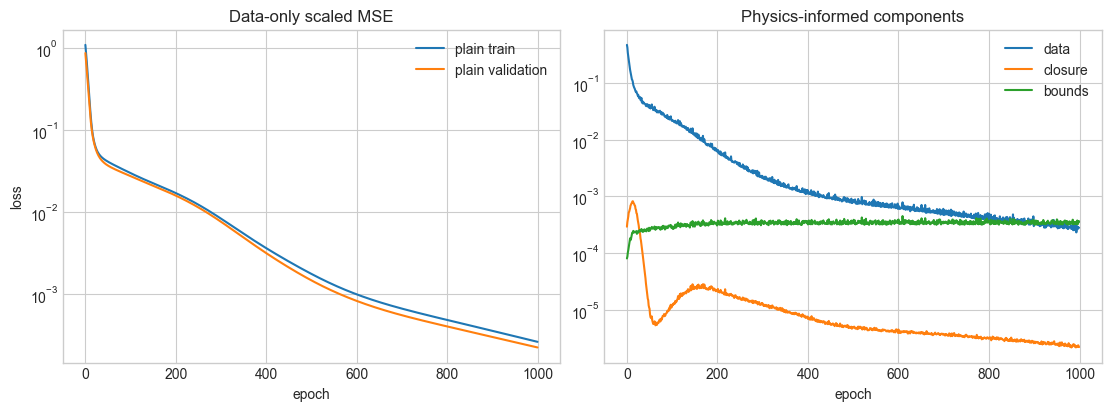

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(plain.trainer.history_.get("loss", []), label="plain train")
if "val_loss" in plain.trainer.history_:
    axes[0].plot(plain.trainer.history_["val_loss"], label="plain validation")
axes[0].set_title("Data-only scaled MSE")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_yscale("log")
axes[0].legend(frameon=False)

axes[1].plot(physics_history["data_loss"], label="data")
axes[1].plot(physics_history["closure_loss"], label="closure")
bounds_history_key = "bounds_loss" if "bounds_loss" in physics_history else "bound_loss"
axes[1].plot(physics_history[bounds_history_key], label="bounds")
axes[1].set_yscale("log")
axes[1].set_title("Physics-informed components")
axes[1].set_xlabel("epoch")
axes[1].legend(frameon=False)
plt.show()


## Accuracy and Physics Comparison

Supervised metrics (left) beside physics diagnostics on the test set (right).
With constraint weighting both models reach essentially the same accuracy — test
MAE 4.3e-4 (plain) vs 4.6e-4 (physics) — so the penalty costs almost nothing on
the data fit. Its payoff is on the **balance** diagnostic: the mean normalized
steady-state residual `||r/F||₂` drops ~20% (4.3e-3 → 3.5e-3). The closure and
bound columns move only marginally — and the `XA`/`XG` "violation" columns are
dominated by the data distribution (the test set spans operating points that are
genuinely infeasible, so even the exact labels show large violations there)
rather than by surrogate error.


In [ ]:
comparison_metrics = pd.concat([plain_metrics, physics_metrics], ignore_index=True)
comparison_physics = pd.DataFrame([
    physics_report("exact labels", X_test, y_test),
    physics_report("plain tanh", X_test, plain.predict(X_test)),
    physics_report("physics-informed tanh", X_test, physics_network.predict(X_test)),
])

display(comparison_metrics)
display(comparison_physics)

,split,MAE,MSE,RMSE,R2,n_samples
0,plain train,0.000334,2.763538e-07,0.000526,0.999796,144
1,plain validation,0.000372,3.099681e-07,0.000557,0.999745,48
2,plain test,0.000432,6.247201e-07,0.000790,0.999565,48
3,physics train,0.000426,5.800432e-07,0.000762,0.999571,144
4,physics validation,0.000415,5.558188e-07,0.000746,0.999543,48
5,physics test,0.000457,7.609255e-07,0.000872,0.999471,48


,model,balance max |r| [kg/s],balance mean ||r/F||_2,closure max |sumX-1|,XA max violation,XG max violation
0,exact labels,5.135892e-13,4.001026e-15,2.220446e-16,0.036801,0.089100
1,plain tanh,8.975799e-02,4.302431e-03,2.131135e-03,0.035272,0.089624
2,physics-informed tanh,9.142283e-02,3.458618e-03,3.325868e-03,0.034685,0.087860


## Prediction Scatter

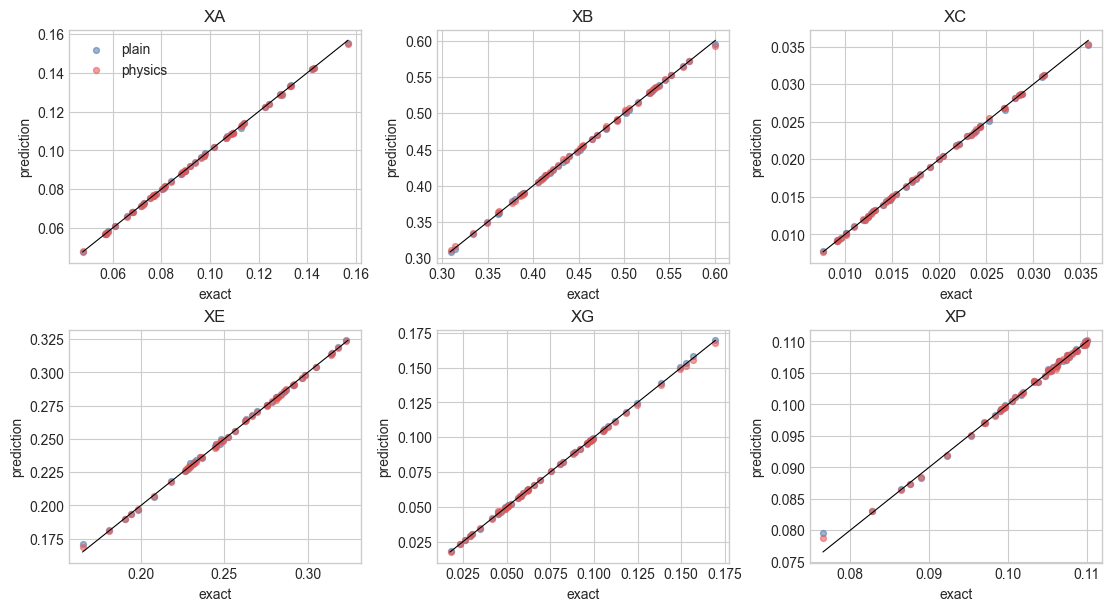

In [ ]:
plain_pred = plain.predict(X_test)
physics_pred = physics_network.predict(X_test)
fig, axes = plt.subplots(2, 3, figsize=(11, 6), constrained_layout=True)
for ax, name, j in zip(axes.ravel(), OUTPUT_NAMES, range(len(OUTPUT_NAMES))):
    ax.scatter(y_test[:, j], plain_pred[:, j], s=18, alpha=0.55, label="plain", color="#4c78a8")
    ax.scatter(y_test[:, j], physics_pred[:, j], s=18, alpha=0.55, label="physics", color="#e45756")
    lo = min(y_test[:, j].min(), plain_pred[:, j].min(), physics_pred[:, j].min())
    hi = max(y_test[:, j].max(), plain_pred[:, j].max(), physics_pred[:, j].max())
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("exact")
    ax.set_ylabel("prediction")
axes.ravel()[0].legend(frameon=False)
plt.show()

## Profit Landscape Comparison

Notebook 02 compared the exact Williams-Otto profit surface with the surrogate-implied profit surface. Here we repeat that comparison for the plain tanh and PI-tanh models on the same operating grid.


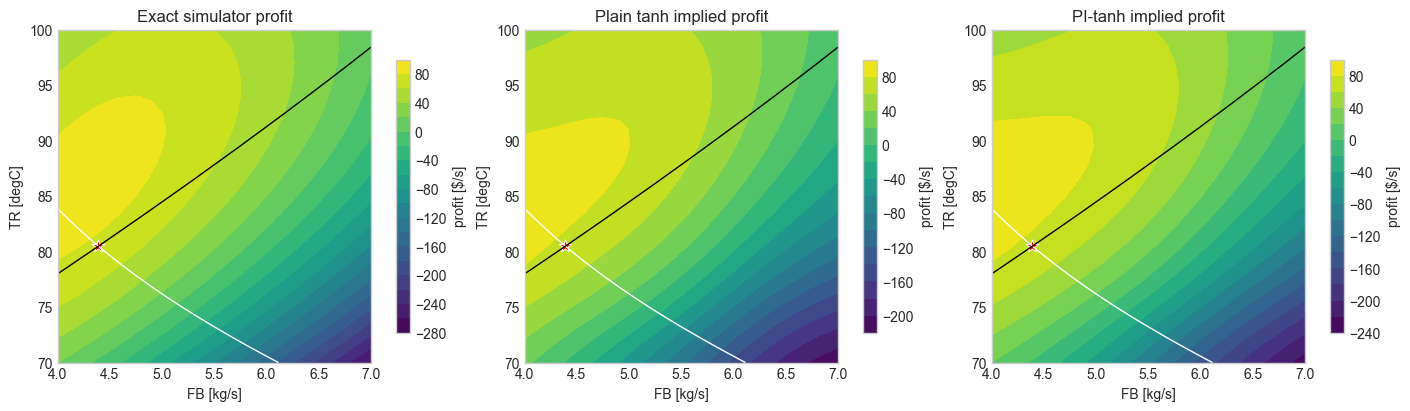

In [ ]:
fb_axis = np.linspace(params.fb_bounds[0], params.fb_bounds[1], 21)
tr_axis = np.linspace(params.tr_bounds[0], params.tr_bounds[1], 21)
FB_grid, TR_grid = np.meshgrid(fb_axis, tr_axis)
grid_X = np.column_stack([FB_grid.ravel(), TR_grid.ravel()])

exact_profit = []
exact_xa = []
exact_xg = []
for fb, tr in grid_X:
    state = solve_steady_state(float(fb), float(tr), params=params)
    exact_profit.append(state.profit)
    exact_xa.append(state.x[OUTPUT_NAMES.index("XA")])
    exact_xg.append(state.x[OUTPUT_NAMES.index("XG")])
exact_profit_grid = np.asarray(exact_profit).reshape(FB_grid.shape)
exact_xa_grid = np.asarray(exact_xa).reshape(FB_grid.shape)
exact_xg_grid = np.asarray(exact_xg).reshape(FB_grid.shape)

plain_grid_pred = plain.predict(grid_X)
physics_grid_pred = physics_network.predict(grid_X)

def profit_from_predictions(predictions, X):
    return np.asarray([
        profit(dict(zip(OUTPUT_NAMES, y_i)), fb=float(x_i[0]), params=params)
        for x_i, y_i in zip(X, predictions)
    ])

plain_profit_grid = profit_from_predictions(plain_grid_pred, grid_X).reshape(FB_grid.shape)
physics_profit_grid = profit_from_predictions(physics_grid_pred, grid_X).reshape(FB_grid.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, values, title in [
    (axes[0], exact_profit_grid, "Exact simulator profit"),
    (axes[1], plain_profit_grid, "Plain tanh implied profit"),
    (axes[2], physics_profit_grid, "PI-tanh implied profit"),
]:
    contour = ax.contourf(FB_grid, TR_grid, values, levels=18, cmap="viridis")
    ax.contour(FB_grid, TR_grid, exact_xa_grid, levels=[params.xa_max], colors="white", linewidths=1.0)
    ax.contour(FB_grid, TR_grid, exact_xg_grid, levels=[params.xg_max], colors="black", linewidths=1.0)
    ax.scatter(EXACT_OPTIMUM["FB"], EXACT_OPTIMUM["TR"], marker="*", s=90, color="red", edgecolor="white", linewidth=0.7)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    fig.colorbar(contour, ax=ax, shrink=0.82, label="profit [$/s]")
plt.show()


## Exact Tanh Embedding Benchmark

This benchmark compares the exact Williams-Otto optimum against the operating points recommended by the data-only tanh and PI-tanh surrogates under the same exact tanh embedding. Each surrogate point is re-evaluated with the exact simulator, and the table reports both the surrogate-side objective and the true process objective.


In [ ]:
def residual_norm_at(fb, tr, outputs):
    values = np.asarray([outputs[name] for name in OUTPUT_NAMES], dtype=float)
    residual = residuals(values, fb=float(fb), tr=float(tr), params=params)
    return float(np.linalg.norm(residual / (params.fa + float(fb))))


def exact_output_dict(state):
    return {name: float(value) for name, value in zip(OUTPUT_NAMES, state.x)}


def operating_constraint_violations(outputs, params=params, tol=1e-8):
    xa_violation = max(float(outputs["XA"]) - params.xa_max, 0.0)
    xg_violation = max(float(outputs["XG"]) - params.xg_max, 0.0)
    violated = []
    if xa_violation > tol:
        violated.append(f"XA <= {params.xa_max:.3f} violated by {xa_violation:.3e}")
    if xg_violation > tol:
        violated.append(f"XG <= {params.xg_max:.3f} violated by {xg_violation:.3e}")
    return {
        "true XA violation": xa_violation,
        "true XG violation": xg_violation,
        "true violated constraints": "; ".join(violated) if violated else "none",
    }


def result_row(label, result, wall_seconds, formulation):
    exact_violations = operating_constraint_violations(result.exact_outputs)
    surrogate_violations = operating_constraint_violations(result.predicted_outputs)
    return {
        "model": label,
        "formulation": formulation,
        "solver": result.solver_name,
        "status": result.status,
        "termination": result.termination_condition,
        "FB": result.fb,
        "TR": result.tr,
        "surrogate objective": result.objective_value,
        "surrogate profit": result.surrogate_profit,
        "true process objective": result.exact_profit,
        "profit gap vs exact": exact_state.profit - result.exact_profit,
        "surrogate residual ||r/F||": residual_norm_at(result.fb, result.tr, result.predicted_outputs),
        "true feasible": result.exact_feasible,
        "true violated constraints": exact_violations["true violated constraints"],
        "true XA": result.exact_outputs["XA"],
        "true XG": result.exact_outputs["XG"],
        "true XA violation": exact_violations["true XA violation"],
        "true XG violation": exact_violations["true XG violation"],
        "surrogate violated constraints": surrogate_violations["true violated constraints"],
        "surrogate XA violation": surrogate_violations["true XA violation"],
        "surrogate XG violation": surrogate_violations["true XG violation"],
        "solve seconds": result.solve_seconds,
        "wall seconds": wall_seconds,
    }


exact_state = solve_steady_state(EXACT_OPTIMUM["FB"], EXACT_OPTIMUM["TR"], params=params)
exact_outputs = exact_output_dict(exact_state)
benchmark_rows = [{
    "model": "exact simulator",
    "formulation": "exact process",
    "solver": "reference",
    "status": "reference",
    "termination": "known benchmark optimum",
    "FB": EXACT_OPTIMUM["FB"],
    "TR": EXACT_OPTIMUM["TR"],
    "surrogate objective": np.nan,
    "surrogate profit": np.nan,
    "true process objective": exact_state.profit,
    "profit gap vs exact": 0.0,
    "surrogate residual ||r/F||": residual_norm_at(EXACT_OPTIMUM["FB"], EXACT_OPTIMUM["TR"], exact_outputs),
    "true feasible": True,
    "true violated constraints": operating_constraint_violations(exact_outputs)["true violated constraints"],
    "true XA": exact_outputs["XA"],
    "true XG": exact_outputs["XG"],
    "true XA violation": operating_constraint_violations(exact_outputs)["true XA violation"],
    "true XG violation": operating_constraint_violations(exact_outputs)["true XG violation"],
    "surrogate violated constraints": "not applicable",
    "surrogate XA violation": np.nan,
    "surrogate XG violation": np.nan,
    "solve seconds": np.nan,
    "wall seconds": np.nan,
}]

for label, network in [
    ("plain tanh", plain.network),
    ("PI tanh", physics_network),
]:
    try:
        tic = time.perf_counter()
        result = solve_surrogate_optimization_model(
            network,
            formulation="tanh_exact",
            solver="ipopt",
            include_operating_constraints=True,
            profit_formulation="bilinear",
        )
        benchmark_rows.append(result_row(label, result, time.perf_counter() - tic, "tanh_exact"))
    except Exception as exc:
        benchmark_rows.append({
            "model": label,
            "formulation": "tanh_exact",
            "solver": "ipopt",
            "status": "skipped",
            "termination": f"{type(exc).__name__}: {exc}",
            "FB": np.nan,
            "TR": np.nan,
            "surrogate objective": np.nan,
            "surrogate profit": np.nan,
            "true process objective": np.nan,
            "profit gap vs exact": np.nan,
            "surrogate residual ||r/F||": np.nan,
            "true feasible": False,
            "true violated constraints": "not solved",
            "true XA": np.nan,
            "true XG": np.nan,
            "true XA violation": np.nan,
            "true XG violation": np.nan,
            "surrogate violated constraints": "not solved",
            "surrogate XA violation": np.nan,
            "surrogate XG violation": np.nan,
            "solve seconds": np.nan,
            "wall seconds": np.nan,
        })

exact_tanh_benchmark = pd.DataFrame(benchmark_rows)
exact_tanh_benchmark


,model,formulation,solver,status,termination,FB,TR,surrogate objective,surrogate profit,true process objective,...,true violated constraints,true XA,true XG,true XA violation,true XG violation,surrogate violated constraints,surrogate XA violation,surrogate XG violation,solve seconds,wall seconds
0,exact simulator,exact process,reference,reference,known benchmark optimum,4.389400,80.495000,NaN,NaN,75.819473,...,none,0.119999,0.080000,0.0,0.000000,not applicable,NaN,NaN,NaN,NaN
1,plain tanh,tanh_exact,ipopt,ok,optimal,4.390759,80.532425,75.708096,75.708096,75.926915,...,XG <= 0.080 violated by 1.229e-04,0.119858,0.080123,0.0,0.000123,none,8.967365e-09,9.828235e-09,0.086193,1.356798
2,PI tanh,tanh_exact,ipopt,ok,optimal,4.389866,80.514051,75.266869,75.266869,75.880592,...,XG <= 0.080 violated by 6.860e-05,0.119932,0.080069,0.0,0.000069,none,7.080236e-09,9.823286e-09,0.070591,0.099491


## Learned vs Exact Operating Constraints

The profit-landscape panels above drew the **exact** `XA = 0.12` and `XG = 0.08`
boundaries. Here we overlay each surrogate's **own** learned boundaries (dashed)
on the exact ones (solid), over the exact profit surface, for the plain and
physics-informed models — the same constraint comparison used in notebooks 01 and
05. The shaded region is where the surrogate *predicts* an operating-limit
violation; the markers are the exact optimum (★) and the operating point each
surrogate selected under the exact-tanh embedding (✗). The closer a model's
dashed lines track the solid ones, the more trustworthy its embedded constraints.

With constraint weighting both models track the exact boundaries closely, so the
selected points sit almost on top of the exact optimum. The second, **zoomed**
panel (a ±0.005 kg/s × ±0.05 °C window around the optimum) is what actually
separates the plain and physics operating points from the true optimum and from
each other.


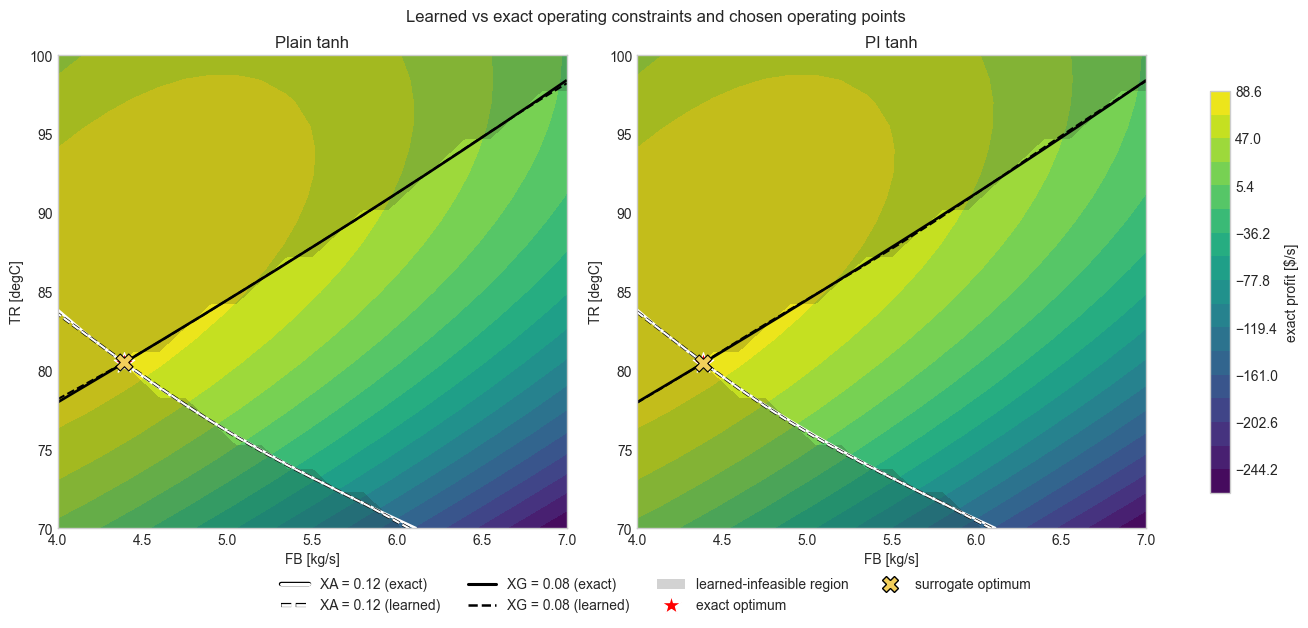

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe


def _learned_field(pred, name):
    return pred[:, OUTPUT_NAMES.index(name)].reshape(FB_grid.shape)


# (panel title, grid predictions, benchmark model key)
panels = [
    ("Plain tanh", plain_grid_pred, "plain tanh"),
    ("PI tanh", physics_grid_pred, "PI tanh"),
]

# Operating point each surrogate selected under the exact-tanh embedding.
selected_xy = {}
for _title, _pred, key in panels:
    row = exact_tanh_benchmark[exact_tanh_benchmark["model"] == key]
    if len(row) and np.isfinite(row["FB"].iloc[0]):
        selected_xy[key] = (float(row["FB"].iloc[0]), float(row["TR"].iloc[0]))

levels = np.linspace(float(exact_profit_grid.min()), float(exact_profit_grid.max()), 18)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
for ax, (title, pred, key) in zip(axes, panels):
    xa_pred = _learned_field(pred, "XA")
    xg_pred = _learned_field(pred, "XG")

    cf = ax.contourf(FB_grid, TR_grid, exact_profit_grid, levels=levels, cmap="viridis")
    infeasible = (xa_pred > params.xa_max) | (xg_pred > params.xg_max)
    ax.contourf(FB_grid, TR_grid, infeasible.astype(float), levels=[0.5, 1.5],
                colors=["0.12"], alpha=0.20)

    # exact operating-limit boundaries (solid)
    ax.contour(FB_grid, TR_grid, exact_xa_grid, levels=[params.xa_max],
               colors="white", linewidths=1.9)
    ax.contour(FB_grid, TR_grid, exact_xg_grid, levels=[params.xg_max],
               colors="black", linewidths=1.9)
    # surrogate's own learned boundaries (dashed)
    learned_xa = ax.contour(FB_grid, TR_grid, xa_pred, levels=[params.xa_max],
                            colors="white", linewidths=1.5, linestyles="--")
    learned_xa.set_path_effects([pe.Stroke(linewidth=2.4, foreground="black"), pe.Normal()])
    ax.contour(FB_grid, TR_grid, xg_pred, levels=[params.xg_max],
               colors="black", linewidths=1.5, linestyles="--")

    ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=240,
               color="red", edgecolor="white", linewidth=0.9, zorder=6)
    if key in selected_xy:
        ax.scatter([selected_xy[key][0]], [selected_xy[key][1]], marker="X", s=150,
                   color="#f2cf5b", edgecolor="black", linewidth=0.8, zorder=6)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")

fig.colorbar(cf, ax=axes, shrink=0.85, label="exact profit [$/s]")
legend_handles = [
    Line2D([0], [0], color="white", lw=2.2,
           path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()],
           label="XA = 0.12 (exact)"),
    Line2D([0], [0], color="white", lw=2.0, ls="--",
           path_effects=[pe.Stroke(linewidth=3.0, foreground="black"), pe.Normal()],
           label="XA = 0.12 (learned)"),
    Line2D([0], [0], color="black", lw=2.2, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="black", lw=1.8, ls="--", label="XG = 0.08 (learned)"),
    Patch(facecolor="0.12", alpha=0.20, label="learned-infeasible region"),
    Line2D([0], [0], marker="*", color="red", markeredgecolor="white", markersize=15,
           ls="", label="exact optimum"),
    Line2D([0], [0], marker="X", color="#f2cf5b", markeredgecolor="black", markersize=11,
           ls="", label="surrogate optimum"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.10))
fig.suptitle("Learned vs exact operating constraints and chosen operating points", y=1.04)
plt.show()


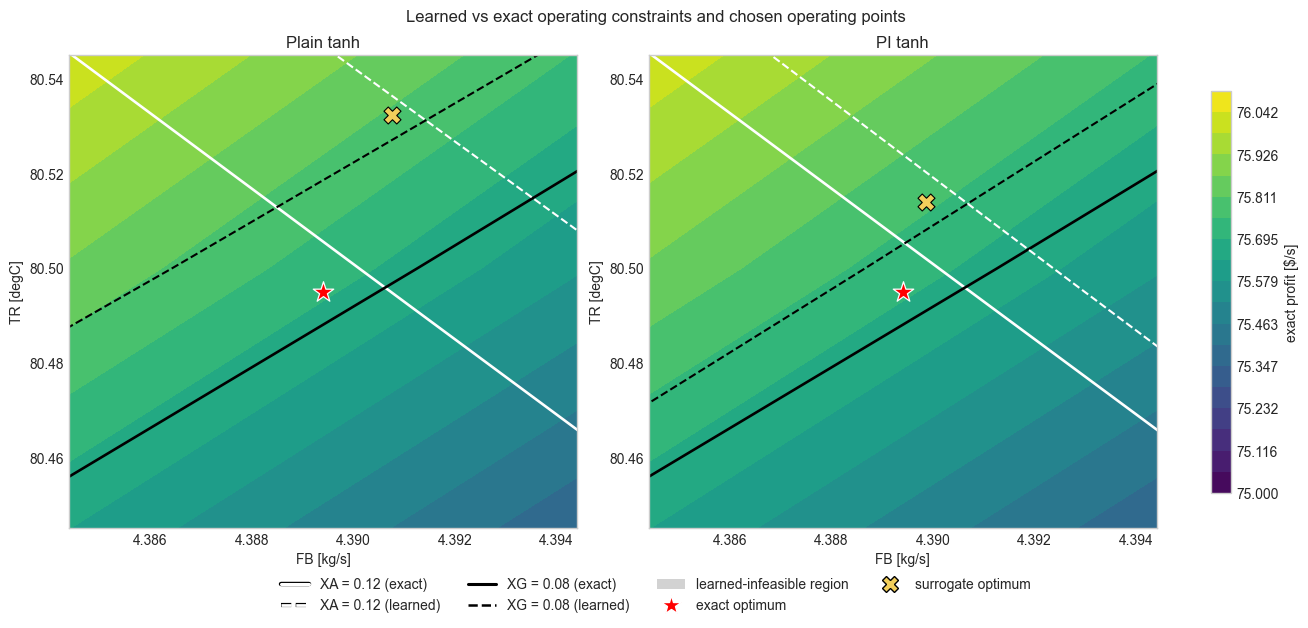

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe


def _learned_field(pred, name):
    return pred[:, OUTPUT_NAMES.index(name)].reshape(FB_grid.shape)


# (panel title, grid predictions, benchmark model key)
panels = [
    ("Plain tanh", plain_grid_pred, "plain tanh"),
    ("PI tanh", physics_grid_pred, "PI tanh"),
]

# Operating point each surrogate selected under the exact-tanh embedding.
selected_xy = {}
for _title, _pred, key in panels:
    row = exact_tanh_benchmark[exact_tanh_benchmark["model"] == key]
    if len(row) and np.isfinite(row["FB"].iloc[0]):
        selected_xy[key] = (float(row["FB"].iloc[0]), float(row["TR"].iloc[0]))

levels = np.linspace(float(75), float(76.1), 20)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
for ax, (title, pred, key) in zip(axes, panels):
    xa_pred = _learned_field(pred, "XA")
    xg_pred = _learned_field(pred, "XG")

    cf = ax.contourf(FB_grid, TR_grid, exact_profit_grid, levels=levels, cmap="viridis")
    infeasible = (xa_pred > params.xa_max) | (xg_pred > params.xg_max)
    #ax.contourf(FB_grid, TR_grid, infeasible.astype(float), levels=[0.5, 1.5],
    #            colors=["0.12"], alpha=0.20)

    # exact operating-limit boundaries (solid)
    ax.contour(FB_grid, TR_grid, exact_xa_grid, levels=[params.xa_max],
               colors="white", linewidths=1.9)
    ax.contour(FB_grid, TR_grid, exact_xg_grid, levels=[params.xg_max],
               colors="black", linewidths=1.9)
    # surrogate's own learned boundaries (dashed)
    learned_xa = ax.contour(FB_grid, TR_grid, xa_pred, levels=[params.xa_max],
                            colors="white", linewidths=1.5, linestyles="--")
    #learned_xa.set_path_effects([pe.Stroke(linewidth=2.4, foreground="black"), pe.Normal()])
    ax.contour(FB_grid, TR_grid, xg_pred, levels=[params.xg_max],
               colors="black", linewidths=1.5, linestyles="--")

    ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=240,
               color="red", edgecolor="white", linewidth=0.9, zorder=6)
    if key in selected_xy:
        ax.scatter([selected_xy[key][0]], [selected_xy[key][1]], marker="X", s=150,
                   color="#f2cf5b", edgecolor="black", linewidth=0.8, zorder=6)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    fbdiff = 0.005
    Trdiff = 0.05
    ax.set_xlim(4.389400-fbdiff, 4.389400+fbdiff)
    ax.set_ylim(80.495000-Trdiff,80.495000+Trdiff)

fig.colorbar(cf, ax=axes, shrink=0.85, label="exact profit [$/s]")
legend_handles = [
    Line2D([0], [0], color="white", lw=2.2,
           path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()],
           label="XA = 0.12 (exact)"),
    Line2D([0], [0], color="white", lw=2.0, ls="--",
           path_effects=[pe.Stroke(linewidth=3.0, foreground="black"), pe.Normal()],
           label="XA = 0.12 (learned)"),
    Line2D([0], [0], color="black", lw=2.2, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="black", lw=1.8, ls="--", label="XG = 0.08 (learned)"),
    Patch(facecolor="0.12", alpha=0.20, label="learned-infeasible region"),
    Line2D([0], [0], marker="*", color="red", markeredgecolor="white", markersize=15,
           ls="", label="exact optimum"),
    Line2D([0], [0], marker="X", color="#f2cf5b", markeredgecolor="black", markersize=11,
           ls="", label="surrogate optimum"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.10))
fig.suptitle("Learned vs exact operating constraints and chosen operating points", y=1.04)
plt.show()


## PWL/MILP Embedding Benchmark

Notebook 03 checks whether tanh networks remain useful after replacing exact tanh activations with piecewise-linear MILP embeddings. This section repeats that benchmark for both the plain tanh and PI-tanh networks using SOS2 and big-M PWL formulations.


In [ ]:
PWL_BREAKPOINTS = 7
pwl_rows = []
for label, network in [
    ("plain tanh", plain.network),
    ("PI tanh", physics_network),
]:
    for formulation in ["tanh_pwl_sos2", "tanh_pwl_bigm"]:
        try:
            tic = time.perf_counter()
            result = solve_surrogate_optimization_model(
                network,
                formulation=formulation,
                solver="gurobi",
                include_operating_constraints=True,
                profit_formulation="piecewise_mccormick",
                breakpoints=PWL_BREAKPOINTS,
                fb_segments=10,
            )
            pwl_rows.append(result_row(label, result, time.perf_counter() - tic, formulation))
        except Exception as exc:
            pwl_rows.append({
                "model": label,
                "formulation": formulation,
                "solver": "gurobi",
                "status": "skipped",
                "termination": f"{type(exc).__name__}: {exc}",
                "FB": np.nan,
                "TR": np.nan,
                "surrogate objective": np.nan,
                "surrogate profit": np.nan,
                "true process objective": np.nan,
                "profit gap vs exact": np.nan,
                "surrogate residual ||r/F||": np.nan,
                "true feasible": False,
                "true violated constraints": "not solved",
                "true XA": np.nan,
                "true XG": np.nan,
                "true XA violation": np.nan,
                "true XG violation": np.nan,
                "surrogate violated constraints": "not solved",
                "surrogate XA violation": np.nan,
                "surrogate XG violation": np.nan,
                "solve seconds": np.nan,
                "wall seconds": np.nan,
            })

pwl_benchmark = pd.DataFrame(pwl_rows)
pwl_benchmark


,model,formulation,solver,status,termination,FB,TR,surrogate objective,surrogate profit,true process objective,...,true violated constraints,true XA,true XG,true XA violation,true XG violation,surrogate violated constraints,surrogate XA violation,surrogate XG violation,solve seconds,wall seconds
0,plain tanh,tanh_pwl_sos2,gurobi,ok,optimal,4.476028,80.250344,72.583421,64.375267,72.161184,...,none,0.118754,0.076611,0.0,0.0,none,0.0,1.804112e-16,0.297373,0.342930
1,plain tanh,tanh_pwl_bigm,gurobi,ok,optimal,4.476028,80.250344,72.583421,64.375267,72.161184,...,none,0.118754,0.076611,0.0,0.0,none,0.0,1.804112e-16,0.519895,0.535077
2,PI tanh,tanh_pwl_sos2,gurobi,ok,optimal,4.478869,79.825471,71.206082,62.963497,70.136756,...,none,0.119926,0.074770,0.0,0.0,none,0.0,1.804112e-16,0.270773,0.283176
3,PI tanh,tanh_pwl_bigm,gurobi,ok,optimal,4.478869,79.825471,71.206082,62.963497,70.136756,...,none,0.119926,0.074770,0.0,0.0,none,0.0,1.804112e-16,0.341048,0.356746


## Architecture and Solve-Time Comparison

Plain tanh and PI-tanh use the same architecture, so this table treats neuron count as a controlled variable and compares optimization solve time and true feasibility under the same embedded formulations.


In [ ]:
def architecture_row(label, network):
    hidden_widths = [layer.weights.shape[1] for layer in network.layers[:-1]]
    return {
        "model": label,
        "inputs": network.n_inputs,
        "outputs": network.n_outputs,
        "hidden layers": len(hidden_widths),
        "hidden widths": hidden_widths,
        "hidden neurons": int(sum(hidden_widths)),
        "parameters": int(sum(layer.weights.size + layer.biases.size for layer in network.layers)),
        "activations": " -> ".join(layer.activation for layer in network.layers),
    }


architecture_comparison = pd.DataFrame([
    architecture_row("plain tanh", plain.network),
    architecture_row("PI tanh", physics_network),
])

solve_time_comparison = pd.concat([
    exact_tanh_benchmark.assign(benchmark="exact tanh NLP"),
    pwl_benchmark.assign(benchmark="PWL/MILP"),
], ignore_index=True)
solve_time_comparison = solve_time_comparison[
    solve_time_comparison["model"].isin(["plain tanh", "PI tanh"])
].merge(architecture_comparison, on="model", how="left")

display(architecture_comparison)
display(solve_time_comparison[[
    "benchmark",
    "model",
    "formulation",
    "solver",
    "status",
    "termination",
    "hidden neurons",
    "parameters",
    "solve seconds",
    "wall seconds",
    "true feasible",
    "true violated constraints",
    "profit gap vs exact",
]].sort_values(["benchmark", "formulation", "model"]).reset_index(drop=True))


,model,inputs,outputs,hidden layers,hidden widths,hidden neurons,parameters,activations
0,plain tanh,2,6,2,"[16, 16]",32,422,tanh -> tanh -> linear
1,PI tanh,2,6,2,"[16, 16]",32,422,tanh -> tanh -> linear


,benchmark,model,formulation,solver,status,termination,hidden neurons,parameters,solve seconds,wall seconds,true feasible,true violated constraints,profit gap vs exact
0,PWL/MILP,PI tanh,tanh_pwl_bigm,gurobi,ok,optimal,32,422,0.341048,0.356746,True,none,5.682718
1,PWL/MILP,plain tanh,tanh_pwl_bigm,gurobi,ok,optimal,32,422,0.519895,0.535077,True,none,3.658289
2,PWL/MILP,PI tanh,tanh_pwl_sos2,gurobi,ok,optimal,32,422,0.270773,0.283176,True,none,5.682718
3,PWL/MILP,plain tanh,tanh_pwl_sos2,gurobi,ok,optimal,32,422,0.297373,0.342930,True,none,3.658289
4,exact tanh NLP,PI tanh,tanh_exact,ipopt,ok,optimal,32,422,0.070591,0.099491,False,XG <= 0.080 violated by 6.860e-05,-0.061118
5,exact tanh NLP,plain tanh,tanh_exact,ipopt,ok,optimal,32,422,0.086193,1.356798,False,XG <= 0.080 violated by 1.229e-04,-0.107441


## Phase-4 Takeaways

- **Constraint weighting lands the boundary outputs.** With the `8×` weighting on
  `XA`/`XG`, both surrogates fit those two outputs among the most accurately of
  the six (plain `XA` 2.4e-4, `XG` 3.5e-4 test MAE) despite the constraint region
  being the sparsest part of the data.
- **The physics penalty is nearly free on accuracy and helps consistency a
  little.** Plain and physics tanh reach the same test MAE (4.3e-4 vs 4.6e-4); in
  return the penalty cuts the mean steady-state balance residual `||r/F||₂` ~20%
  (4.3e-3 → 3.5e-3). Closure/bound diagnostics barely move and are dominated by
  the data distribution, so don't over-read them.
- **The λ tradeoff is flat.** All 9 swept candidates fell inside the 10%
  data-loss tolerance and their physics scores span a razor-thin 0.0202 ±
  0.00002, so the selected `{closure: 0.7, bounds: 13.0}` is essentially
  interchangeable with its neighbours — a single representative weight would do.
- **Under the exact-tanh NLP both surrogates are excellent.** Each lands on the
  true optimum (true profit 75.93 plain / 75.88 physics vs the 75.82 benchmark)
  with only a ~1e-4 `XG` overshoot, solving in well under 0.2 s.
- **The PWL/MILP embedding — not training — dominates the downstream error.** At
  7 breakpoints both surrogates stay feasible but give up real profit versus the
  exact-tanh embedding: plain 72.2 \$/s (gap 3.7) and physics 70.1 \$/s (gap 5.7).
  The physics model is the *more conservative* of the two — it sits further
  inside the `XG` limit (0.075 vs 0.077) and leaves more profit on the table.
  Either way the gap is set by the coarse discretization, so raise the
  breakpoint count before reading much into PWL profit differences.
- **Same size, sub-second everywhere.** Both nets are 32 neurons / 422 params, so
  solve-time differences are model- not size-driven: exact-tanh NLP ~0.07–0.09 s,
  PWL big-M ~0.34–0.52 s.

Next: widen the PWL breakpoint grid to separate discretization error from
surrogate error; if the λ tradeoff stays this flat, collapse the sweep to a
single representative weight; then carry the constraint-weighting + physics
pattern to the hydroformylation surrogate (notebook 07).
